## Sea ice concentration composites by IPO phase

In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.path as mpath
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.patheffects as pe
import cartopy.crs as ccrs
import numpy as np
import datetime
import scipy.signal as signal
import scipy.stats as stats
import os
import glob
import re
import dask
print(datetime.datetime.now())

2024-02-25 11:12:21.439900


In [2]:
from dask_jobqueue import PBSCluster
from dask.distributed import Client

cluster = PBSCluster(cores    = 1,
                     memory   = '5GB',
                     queue    = 'casper',
                     walltime = '05:55:00',
                     project  = 'UCUB0084',
                    )

cluster.scale(10)
client = Client(cluster)
client

Connection method: Cluster object,Cluster type: dask_jobqueue.PBSCluster
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/cwpowell/high_mem/proxy/8787/status,
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/cwpowell/high_mem/proxy/8787/status,Workers: 0
Total threads: 0,Total memory: 0 B
Comm: tcp://128.117.208.112:42301,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/cwpowell/high_mem/proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B


In [2]:
model_names = [
    'ACCESS-ESM1-5', 'CanESM5', 'CESM2-LENS', 'CESM2-LENS-SMBB', 'EC-Earth3',
    'MIROC6', 'MPI-ESM1-2-LR', 'CanESM2', 'CESM1',
]

CLIVAR_names = {
    'CanESM2':'canesm2_lens', 'CESM1':'cesm_lens',
    'GFDL-ESM2M':'gfdl_esm2m_lens', 'MPI-ESM1':'mpi_lens'
}

model_center = {
    'EC-Earth3':'EC-Earth-Consortium', 'CanESM5':'CCCma', 'CESM2-LENS':'NCAR',
    'MIROC6':'MIROC', 'ACCESS-ESM1-5':'CSIRO', 'MPI-ESM1-2-LR':'MPI-M',
    'CanESM2':'canesm2_lens', 'CESM1':'cesm_lens', 
    'GFDL-ESM2M':'gfdl_esm2m_lens', 'MPI-ESM1':'mpi_lens'
}

xr_new_time = xr.open_dataarray(
    '/glade/work/cwpowell/low-frequency-variability/raw_data/'\
    +'datetime64_1850_2100_monthly.nc')

In [3]:
#import the SIE data from all models
SIE_sep_GCMs = {}

for GCM_ in model_names:
    print(GCM_)
    
    SIE_model = []
    
    mem_list = np.ravel(np.sort([
        re.findall(f'SIA_SIE_{GCM_}_(.*)_historical_2100.nc', i) for i in 
        glob.glob('/glade/work/cwpowell/ice-free/'\
        f'sea_ice_data/SIA_SIE_{GCM_}_*_historical_2100.nc')
    ]))
    
    for mem_ in mem_list:
        temp_data = xr.open_dataset('/glade/work/cwpowell/ice-free/'\
            f'sea_ice_data/SIA_SIE_{GCM_}_{mem_}_historical_2100.nc')
        
        SIE_model.append(temp_data)
        
    SIE_model = xr.concat((SIE_model),dim='member')
    SIE_model['member'] = mem_list
    SIE_model = SIE_model['Arctic_SIE'].sel(time=SIE_model['time.month']==9)
    
    SIE_model['time'] = np.arange(int(SIE_model['time.year'].min().values),
                                  int(SIE_model['time.year'].max().values)+1)
    
    SIE_model = SIE_model.rename({'time':'year'})
    
    
    SIE_sep_GCMs[GCM_] = SIE_model

ACCESS-ESM1-5
CanESM5
CESM2-LENS
CESM2-LENS-SMBB
EC-Earth3
MIROC6
MPI-ESM1-2-LR
CanESM2
CESM1


## Compute composite SIC plots

In [4]:
#calculate ice free year for 11 year running means
sep_SIE_11yr = {}

for model_name in model_names:
    sep_SIE_11yr[model_name] = SIE_sep_GCMs[model_name].rolling(
        year=11, center=True).mean()
    
sep_SIE_11yr['CanESM5'] = sep_SIE_11yr['CanESM5'].drop_sel(member='r1i1p1f1')

In [5]:
#load the IPO derived from the TPI index
IPO_models = {}

base_path = '/glade/work/cwpowell/low-freq-trajectories/SST_for_IPO/IPO_per_Screen_Deser/'
file_name = '_11yr_annual_av_TPI.nc'

for model_name in model_names:
    if model_name in ['CESM2-LENS','CESM2-LENS-SMBB']:
        temp = xr.open_dataarray(base_path+'CESM2-LENS'+file_name)
        
        IPO_models[model_name] = temp.sel(
            member=sep_SIE_11yr[model_name]['member'])
    
    elif model_name in ['CanESM2', 'CESM1', 'GFDL-ESM2M', 'MPI-ESM1']:
        temp = xr.open_dataarray(base_path+model_name+file_name)
        
        if model_name == 'MPI-ESM1':
            temp['member'] = ['r{}i2005p3'.format(str(mem_).zfill(3))
                              for mem_ in temp['member'].values]
        else:
            temp['member'] = [f'r{mem_}i1p1' for mem_ in temp['member'].values]
            
        IPO_models[model_name] = temp.sortby('member')
    
    else:
        IPO_models[model_name] = xr.open_dataarray(base_path+model_name+file_name)

IPO_models['CanESM5'] = IPO_models['CanESM5'].drop_sel(member='r1i1p1f1')

In [9]:
def load_SIC(GCM_, var_ID):
    '''
    Load the sea ice concentration data for a given model, member and 
    year range from start year to start_year+55 years.
    Use both the historical and future RCP8.5 for CMIP5 or SSP370 CMIP6 simulations.

    Parameters
    ----------
    model_name: string
        The name of the model e.g. CanESM5
    var_ID: string
        Variant ID e.g. 'r1ip1f1' where the letters correspond to:
        r<>: realisation (i.e. ensemble member),
        i<>: initialisation method, p<>: physics, f<>: forcing
    start_yr: int
        The starting year of the selected trajectory

    Returns
    ----------
        xarray.Dataset with variable siconc
    '''  
    ######### load the arecello files #############
    if GCM_ == 'CESM2-LENS-SMBB':
        areacello_ = xr.open_dataset(
        '/glade/work/cwpowell/low-frequency-variability/'\
        +'raw_data/masie_masks/areacello_CESM2-LENS_30N.nc')
    else:
        areacello_ = xr.open_dataset(
            '/glade/work/cwpowell/low-frequency-variability/'\
            +'raw_data/masie_masks/areacello_{}_30N.nc'.format(GCM_)
        )

    if GCM_ in ['CESM2-LENS','CESM2-LENS-SMBB']:
        areacello_ = areacello_.rename({'nlat':'nj', 'nlon':'ni'})
    
    elif GCM_ == 'CESM1':
        areacello_ = areacello_.rename({'nlat':'j', 'nlon':'i'})
        
    areacello_with_nan = areacello_['areacello']
    
    ####### make the paths for historical and futrue simulations on glade ####    
    if GCM_ == 'CESM2-LENS':
        hist_paths = glob.glob(
            '/glade/campaign/cgd/cesm/CESM2-LE/timeseries/ice/proc/tseries/'
            f'month_1/aice/*BHISTcmip6*{var_ID}*.nc')
        
        fut_paths = glob.glob(
            '/glade/campaign/cgd/cesm/CESM2-LE/timeseries/ice/proc/tseries/'
            f'month_1/aice/*370cmip6*{var_ID}*.nc')

    elif  GCM_ == 'CESM2-LENS-SMBB':
        hist_paths = glob.glob(
            '/glade/campaign/cgd/cesm/CESM2-LE/timeseries/ice/proc/tseries/'
            f'month_1/aice/*BHISTsmbb*{var_ID}*.nc')

        fut_paths = glob.glob(
            '/glade/campaign/cgd/cesm/CESM2-LE/timeseries/ice/proc/tseries/'
            f'month_1/aice/*370smbb*{var_ID}*.nc')
        
    elif GCM_ in ['CanESM2', 'CESM1', 'GFDL-ESM2M']:
        hist_paths = glob.glob(
            f'/glade/collections/cdg/data/CLIVAR_LE/{model_center[GCM_]}/'\
            f'OImon/sic/*historical_rcp85_{var_ID}*.nc')
        fut_paths = ['foo']
    
    elif GCM_ == 'MPI-ESM1':
        hist_paths = glob.glob(
            f'/glade/collections/cdg/data/CLIVAR_LE/{model_center[GCM_]}/'\
            f'OImon/sic/*historical_{var_ID[:4]}*.nc')
        fut_paths = glob.glob(
            f'/glade/collections/cdg/data/CLIVAR_LE/{model_center[GCM_]}/'\
            f'OImon/sic/*rcp85_{var_ID[:4]}*.nc')
        
    else:
        var_name = 'siconc'
        base_hist = '/glade/collections/cmip/CMIP6/CMIP/'\
           +f'{model_center[GCM_]}/{GCM_}/historical/{var_ID}/SImon/'\
           +f'{var_name}'
        
        grid_ID = os.listdir(base_hist)[0]
        version = os.listdir(base_hist+f'/{grid_ID}/')[0]
        
        hist_paths = glob.glob(
            base_hist+f'/{grid_ID}/{version}/{var_name}/*.nc')
        
        base_ssp370 = '/glade/collections/cmip/CMIP6/ScenarioMIP/'\
           +f'{model_center[GCM_]}/{GCM_}/ssp370/{var_ID}/SImon/'\
           +f'{var_name}'
        
        grid_ID = os.listdir(base_ssp370)[0]
        version = os.listdir(base_ssp370+f'/{grid_ID}/')[0]
        
        fut_paths = glob.glob(
            base_ssp370+f'/{grid_ID}/{version}/{var_name}/*.nc')
    
    ########################### load the data files ############################
    
    #load the SIC data and select above 30N        
    if GCM_ in ['CanESM2','CESM1','GFDL-ESM2M']:
        SIC = xr.open_mfdataset(hist_paths, combine='nested', 
            concat_dim='time', chunks={'time':120}).sortby('time')
    else:
        with dask.config.set(**{'array.slicing.split_large_chunks': True}):
            hist_data = xr.open_mfdataset(hist_paths, combine='nested', 
                                          concat_dim='time', chunks={'time':120})
    
            fut_data =  xr.open_mfdataset(fut_paths, combine='nested', 
                                          concat_dim='time', chunks={'time':120})

        SIC = xr.concat((hist_data, fut_data), dim='time').sortby('time')
    
    #remove concentration values below 30N and convert to fraction from %
    if GCM_ in ['CESM2-LENS','CESM2-LENS-SMBB']:
        SIC = SIC['aice'].where(areacello_with_nan, drop=False)
        
    elif GCM_ in ['CanESM2', 'CESM1', 'MPI-ESM1']:
        SIC = SIC['sic'].where(areacello_with_nan, drop=False)/100
        
    elif GCM_ == 'GFDL-ESM2M':
        SIC = SIC['sic'].where(areacello_with_nan, drop=False)
        
    else:
        SIC = SIC['siconc'].where(areacello_with_nan, drop=False)/100
  
    #replace time with datetime64 for consistency across models
    if GCM_ == 'EC-Earth3' and var_ID not in [
        'r9i1p1f1', 'r6i1p1f1', 'r4i1p1f1', 'r1i1p1f1', 'r11i1p1f1', 
        'r15i1p1f1', 'r13i1p1f1',
    ]:
        #EC-Earth files on /glade often only go back to 1970
        SIC['time'] = xr_new_time.sel(time=slice('1970-01','2100-12'))
        
    elif GCM_ in ['CanESM2', 'GFDL-ESM2M']:
        SIC['time'] = xr_new_time.sel(time=slice('1950-01','2100-12'))
        
    elif GCM_ == 'CESM1':
        if var_ID == 'r1i1p1':
            SIC['time'] = xr_new_time.sel(time=slice('1850-01','2100-12'))
            SIC = SIC.sel(time=slice('1920-01','2100-12'))
        else:
            SIC['time'] = xr_new_time.sel(time=slice('1920-01','2100-12'))
        
    elif GCM_ == 'MPI-ESM1':
        SIC['time'] = xr_new_time.sel(time=slice('1850-01','2099-12'))
        
    else:
        SIC['time'] = xr_new_time
    
    ################ select on the specified times ##################    
    if GCM_ in ['CESM2-LENS','CESM2-LENS-SMBB','CESM1']:
        SIC_reduced = SIC.sel(time=SIC['time.month']==10)
    else:
        SIC_reduced = SIC.sel(time=SIC['time.month']==9)
    
    final_dataset = xr.Dataset({'SIC_trajectory':SIC_reduced})
    
    if GCM_ not in ['CESM2-LENS','CESM2-LENS-SMBB','CESM1','CanESM2','GFDL-ESM2M','MPI-ESM1']:
        final_dataset = final_dataset.drop('type')
    
    return(final_dataset)

In [10]:
#save to SIC trajectories to NetCDF
for model_name in ['MPI-ESM1-2-LR','CanESM2','CESM2-LENS','CESM2-LENS-SMBB','EC-Earth3','MIROC6']:
    
    print(datetime.datetime.now(), model_name)
    
    if model_name in ['GFDL-ESM2M','MPI-ESM1']:
        continue

    IPO_pos_mem_used = []
    IPO_neg_mem_used = []
    IPO_pos_ = []
    IPO_neg_ = []
    all_mem_ = []
    
    for start_SIE in np.arange(4.2,5.21,0.1):
        
        IPO_pos_mem = []
        IPO_neg_mem = []
        all_mem_mem = []
        
        for mem_ in IPO_models[model_name]['member']:
            
            SIC_Sep = load_SIC(model_name, mem_)
            
            #find latest matching year to SIE, define start_year
            start_yr_mem = int(sep_SIE_11yr[model_name]['year'].where(
                (sep_SIE_11yr[model_name].sel(member=mem_) - start_SIE) < 0).min('year'))

            #change actual years to trajectory years, select 0-55
            if model_name == 'MIROC6':
                SIC_reduced = SIC_Sep.sel(time=slice(str(start_yr_mem), str(start_yr_mem+54)))
                SIC_reduced['time'] = np.arange(0,55)
            else:
                SIC_reduced = SIC_Sep.sel(time=slice(str(start_yr_mem), str(start_yr_mem+55)))
                SIC_reduced['time'] = np.arange(0,56)
            
            SIC_reduced = SIC_reduced.rename({'time':'trajectory_year'})

            #determine IPO phase by 10-year persistence
            IPO_pos = (IPO_models[model_name].sel(member=mem_).sel(
                year=slice(start_yr_mem-9,start_yr_mem))>0).min('year')==True
            IPO_neg = (IPO_models[model_name].sel(member=mem_).sel(
                year=slice(start_yr_mem-9,start_yr_mem))<0).min('year')==True
            
            if IPO_pos:
                IPO_pos_mem.append(SIC_reduced)
                IPO_pos_mem_used.append(mem_.values)
            elif IPO_neg:
                IPO_neg_mem.append(SIC_reduced)
                IPO_neg_mem_used.append(mem_.values)

            all_mem_mem.append(SIC_reduced)
        
        #if no examples of both criteria being fulfilled, instead append the 
        #ensemble mean
        ens_mean = xr.concat((all_mem_mem),dim='member').mean('member')
            
        #also collect up all the IPO pos/neg irrespective of PARC if length none
        if len(IPO_pos_mem) < 1:
            IPO_pos_ = [ens_mean]
        if len(IPO_neg_mem) < 1:
            IPO_neg_ = [ens_mean]

        IPO_pos_.append(xr.concat((IPO_pos_mem),dim='member').mean('member'))
        IPO_neg_.append(xr.concat((IPO_neg_mem),dim='member').mean('member'))
        IPO_pos_SD.append(xr.concat((IPO_pos_mem),dim='member').std('member'))
        IPO_neg_SD.append(xr.concat((IPO_neg_mem),dim='member').std('member'))
        
        all_mem_.append(xr.concat((all_mem_mem),dim='member'))
        
    #compute the averages across starting SIE before saving occurs
    IPO_pos_xr = xr.concat((IPO_pos_), dim='start_SIE').mean('start_SIE').compute()
    IPO_pos_xr.to_netcdf('/glade/work/cwpowell/ice-free/SIC_trajectories/'\
        f'SIC_traj_IPO_pos_only_start_42_52_sq_km_{model_name}.nc')
    print(datetime.datetime.now(), 'Done IPO+')
    
    IPO_neg_xr = xr.concat((IPO_neg_), dim='start_SIE').mean('start_SIE').compute()
    IPO_neg_xr.to_netcdf('/glade/work/cwpowell/ice-free/SIC_trajectories/'\
        f'SIC_traj_IPO_neg_only_start_42_52_sq_km_{model_name}.nc')
    print(datetime.datetime.now(), 'Done IPO-')

    all_mem_xr = xr.concat((all_mem_),dim='start_SIE').mean('start_SIE').compute()
    all_mem_xr.to_netcdf('/glade/work/cwpowell/ice-free/SIC_trajectories/'\
                        f'SIC_traj_ensemble_start_42_52_sq_km_{model_name}.nc')
    print(datetime.datetime.now(), 'Done Ens')
    
    all_mem_xr = xr.concat((all_mem_),dim='start_SIE').mean('start_SIE').mean('member').compute()
    all_mem_xr.to_netcdf('/glade/work/cwpowell/ice-free/SIC_trajectories/'\
                        f'SIC_traj_ensemble_mean_start_42_52_sq_km_{model_name}.nc')
    print(datetime.datetime.now(), 'Done Ens Mean')

    IPO_pos_xr = xr.concat((IPO_pos_SD), dim='start_SIE').mean('start_SIE').compute()
    IPO_pos_xr.attrs = {'Members used':IPO_pos_mem_used}
    IPO_pos_xr.to_netcdf('/glade/work/cwpowell/ice-free/SIC_trajectories/'\
        f'SIC_traj_IPO_pos_only_SD_start_42_52_sq_km_{model_name}.nc')
    print(datetime.datetime.now(), 'Done IPO+')
    
    IPO_neg_xr = xr.concat((IPO_neg_SD), dim='start_SIE').mean('start_SIE').compute()
    IPO_neg_xr.attrs = {'Members used':IPO_neg_mem_used}
    IPO_neg_xr.to_netcdf('/glade/work/cwpowell/ice-free/SIC_trajectories/'\
        f'SIC_traj_IPO_neg_only_SD_start_42_52_sq_km_{model_name}.nc')
    print(datetime.datetime.now(), 'Done IPO-')

2024-02-09 15:00:52.678586 MPI-ESM1-2-LR
2024-02-09 15:13:22.163958 Done IPO+
2024-02-09 15:13:25.198576 Done IPO-
2024-02-09 15:13:25.198647 CanESM2
2024-02-09 16:35:24.678332 Done IPO+
2024-02-09 16:35:40.142486 Done IPO-
2024-02-09 16:35:40.142680 CESM2-LENS-SMBB
2024-02-09 17:54:19.304081 Done IPO+
2024-02-09 17:54:33.686055 Done IPO-
2024-02-09 17:54:33.686348 EC-Earth3
2024-02-09 20:31:29.663291 Done IPO+
2024-02-09 20:31:54.287719 Done IPO-
2024-02-09 20:31:54.287785 MIROC6


/glade/u/apps/opt/conda/envs/npl-2022b/lib/python3.8/site-packages/xarray/core/indexing.py:1374: PerformanceWarning: Slicing is producing a large chunk. To accept the large
chunk and silence this warning, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': False}):
    ...     array[indexer]

To avoid creating the large chunks, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    ...     array[indexer]
  return self.array[key]
/glade/u/apps/opt/conda/envs/npl-2022b/lib/python3.8/site-packages/xarray/core/indexing.py:1374: PerformanceWarning: Slicing is producing a large chunk. To accept the large
chunk and silence this warning, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': False}):
    ...     array[indexer]

To avoid creating the large chunks, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    ...     array[indexer]
  return self.arr

2024-02-09 20:48:45.740474 Done IPO+
2024-02-09 20:49:05.529077 Done IPO-


In [32]:
all_realizations_IPO_pos_PARC_pos = xr.concat((SIC_traj_IPO_pos_PARC_pos),dim='realization')
all_realizations_IPO_pos_PARC_neg = xr.concat((SIC_traj_IPO_pos_PARC_neg),dim='realization')
if model_name == 'MPI-ESM1-2-LR':
    all_realizations_IPO_neg_PARC_pos = all_realizations_IPO_pos_PARC_neg*np.nan
else:
    all_realizations_IPO_neg_PARC_pos = xr.concat((SIC_traj_IPO_neg_PARC_pos),dim='realization')
all_realizations_IPO_neg_PARC_neg = xr.concat((SIC_traj_IPO_neg_PARC_neg),dim='realization')
all_realizations_all = xr.concat((SIC_traj_all),dim='realization')

In [33]:
all_realizations_net = (all_realizations_all 
                        - all_realizations_all.sel(trajectory_year=0)).mean('realization')

all_realizations_IPO_pos_PARC_pos_net = (all_realizations_IPO_pos_PARC_pos 
                                         - all_realizations_IPO_pos_PARC_pos.sel(trajectory_year=0)) - all_realizations_net

all_realizations_IPO_neg_PARC_pos_net = (all_realizations_IPO_neg_PARC_pos 
                                         - all_realizations_IPO_neg_PARC_pos.sel(trajectory_year=0)) - all_realizations_net

all_realizations_IPO_pos_PARC_neg_net = (all_realizations_IPO_pos_PARC_neg 
                                         - all_realizations_IPO_pos_PARC_neg.sel(trajectory_year=0)) - all_realizations_net

all_realizations_IPO_neg_PARC_neg_net = (all_realizations_IPO_neg_PARC_neg 
                                         - all_realizations_IPO_neg_PARC_neg.sel(trajectory_year=0)) - all_realizations_net

In [21]:
all_realizations_IPO_neg_PARC_neg_net.isel(realization=0).sel(trajectory_year=20)

<xarray.DataArray 'SIC_trajectory' (lat: 64, lon: 128)>
dask.array<getitem, shape=(64, 128), dtype=float32, chunksize=(64, 128), chunktype=numpy.ndarray>
Coordinates:
  * lat              (lat) float64 -87.86 -85.1 -82.31 ... 82.31 85.1 87.86
  * lon              (lon) float64 0.0 2.812 5.625 8.438 ... 351.6 354.4 357.2
    trajectory_year  int64 20

2024-02-05 19:39:44.088256 ++
2024-02-05 19:40:02.554571 -+
2024-02-05 19:40:14.078660 +-
2024-02-05 19:40:26.199409 --


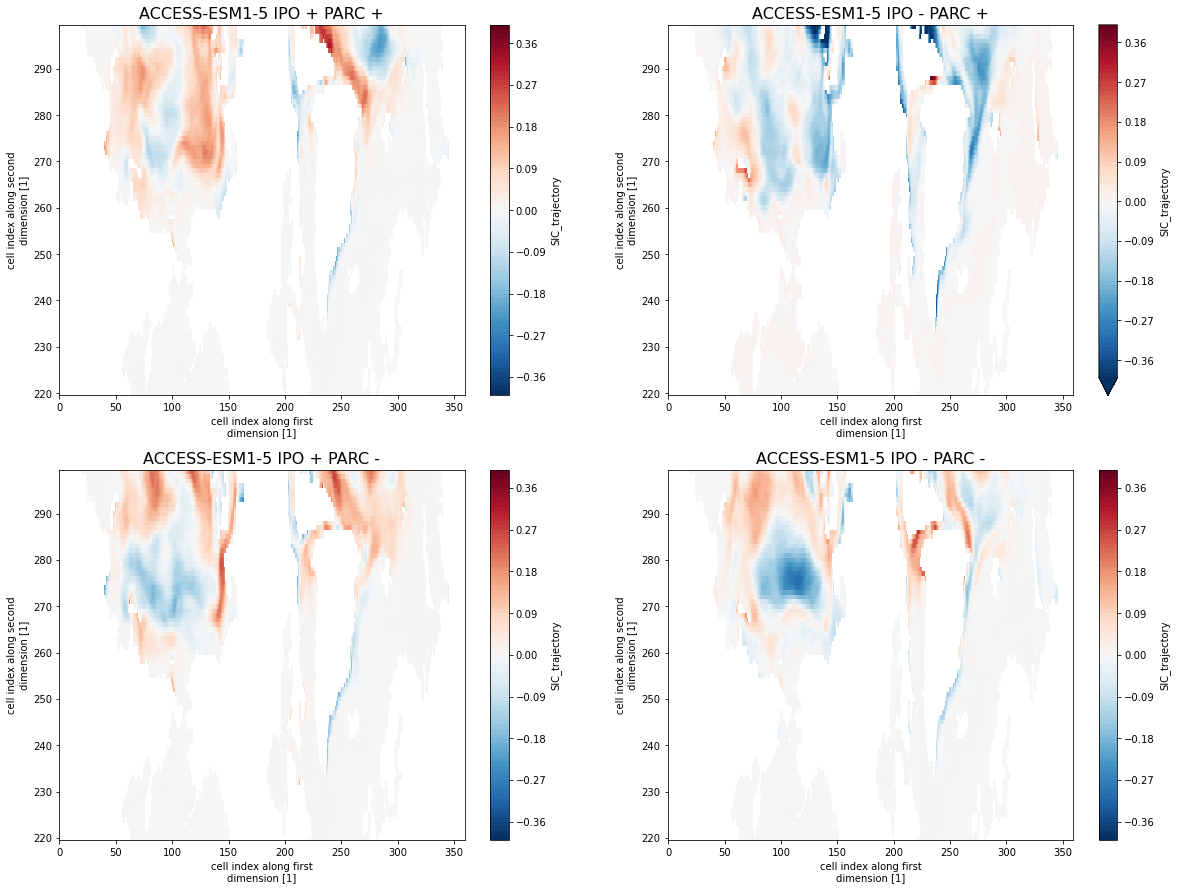

In [35]:
#non polar plots
j_min = 220

fig = plt.figure(figsize=[20,15])

for phase_i in range(4):

    ax = fig.add_subplot(2,2,phase_i+1) 

    if phase_i == 0:
        print(datetime.datetime.now(), '++')
        all_realizations_IPO_pos_PARC_pos_net.mean('realization').sel(trajectory_year=29).sel(j=slice(j_min,None)).plot(
            levels=np.arange(-0.4,0.41,0.01))
        ax.set_title(f'{model_name} IPO + PARC +', fontsize=16)
    elif phase_i == 1:
        print(datetime.datetime.now(), '-+')
        all_realizations_IPO_neg_PARC_pos_net.mean('realization').sel(trajectory_year=29).sel(j=slice(j_min,None)).plot(
            ax=ax, levels=np.arange(-0.4,0.41,0.01))
        ax.set_title(f'{model_name} IPO - PARC +', fontsize=16)
    elif phase_i == 2:
        print(datetime.datetime.now(), '+-')
        all_realizations_IPO_pos_PARC_neg_net.mean('realization').sel(trajectory_year=29).sel(j=slice(j_min,None)).plot(
            ax=ax, levels=np.arange(-0.4,0.41,0.01))
        ax.set_title(f'{model_name} IPO + PARC -', fontsize=16)
    elif phase_i == 3:
        print(datetime.datetime.now(), '--')
        all_realizations_IPO_neg_PARC_neg_net.mean('realization').sel(trajectory_year=29).sel(j=slice(j_min,None)).plot(
            ax=ax, levels=np.arange(-0.4,0.41,0.01))
        ax.set_title(f'{model_name} IPO - PARC -', fontsize=16)